# **ORDER DELIVERY TIME** **PREDICTION**

## Import essential libraries for data manipulation and analysis

In [ ]:
import os
import sys
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
from datetime import datetime
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, KFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV, Ridge, Lasso
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.impute import SimpleImputer
import joblib

print("Python", sys.version)
print("Libraries loaded.")


Python 3.12.11 (main, Jun  4 2025, 08:56:18) [GCC 11.4.0]
Libraries loaded.


# **1.Loading the data**

In [ ]:
# 1. Load the data
possible = [
    '/content/porter_data_1.csv',
    '/mnt/data/porter_data_1.csv',
    './porter_data_1.csv'
]
csv_path = None
for p in possible:
    if os.path.exists(p):
        csv_path = p
        break
if csv_path is None:
    raise FileNotFoundError('porter_data_1.csv not found. Upload the CSV to /content or /mnt/data or current directory.')

df = pd.read_csv(csv_path)
print('Loaded', csv_path, 'with shape', df.shape)
df.head()

Loaded /content/porter_data_1.csv with shape (175777, 14)


,market_id,created_at,actual_delivery_time,store_primary_category,order_protocol,total_items,subtotal,num_distinct_items,min_item_price,max_item_price,total_onshift_dashers,total_busy_dashers,total_outstanding_orders,distance
0,1.0,2015-02-06 22:24:17,2015-02-06 23:11:17,4,1.0,4,3441,4,557,1239,33.0,14.0,21.0,34.44
1,2.0,2015-02-10 21:49:25,2015-02-10 22:33:25,46,2.0,1,1900,1,1400,1400,1.0,2.0,2.0,27.60
2,2.0,2015-02-16 00:11:35,2015-02-16 01:06:35,36,3.0,4,4771,3,820,1604,8.0,6.0,18.0,11.56
3,1.0,2015-02-12 03:36:46,2015-02-12 04:35:46,38,1.0,1,1525,1,1525,1525,5.0,6.0,8.0,31.80
4,1.0,2015-01-27 02:12:36,2015-01-27 02:58:36,38,1.0,2,3620,2,1425,2195,5.0,5.0,7.0,8.20


#**2.Data Preprocessing and Feature Engineering**

##2.1 Fixing the Datatypes

In [ ]:
# 2. Data Preprocessing and Feature Engineering
# 2.1 Fixing the datatypes

# 2.1.1 Convert created_at & actual_delivery_time to datetime (2 marks)
for col in ['created_at', 'actual_delivery_time']:
    if col in df.columns:
        df[col] = pd.to_datetime(df[col], infer_datetime_format=True, errors='coerce')

print('Datetime conversion done. Nulls after conversion:')
print(df[['created_at','actual_delivery_time']].isnull().sum())

# 2.1.2 Convert categorical fields to category dtype (3 marks)
cat_cols = []
for c in ['store_primary_category','order_protocol','market_id']:
    if c in df.columns:
        df[c] = df[c].astype('category')
        cat_cols.append(c)
print('Converted to category:', cat_cols)
df.dtypes

Datetime conversion done. Nulls after conversion:
created_at              0
actual_delivery_time    0
dtype: int64
Converted to category: ['store_primary_category', 'order_protocol', 'market_id']


,0
market_id,category
created_at,datetime64[ns]
actual_delivery_time,datetime64[ns]
store_primary_category,category
order_protocol,category
total_items,int64
subtotal,int64
num_distinct_items,int64
min_item_price,int64
max_item_price,int64


In [ ]:
# 2.2 Feature Engineering (5 marks)

# 2.2.1 Calculate time taken (2 marks)
df['time_taken'] = (df['actual_delivery_time'] - df['created_at']).dt.total_seconds() / 60.0

# Basic cleanup: remove non-positive or null durations
before = df.shape[0]
df = df[df['time_taken'].notnull() & (df['time_taken'] > 0)].copy()
after = df.shape[0]
print(f'Removed {before-after} rows with invalid durations. New shape: {df.shape}')

# 2.2.2 Extract hour and day, create isWeekend, drop unnecessary columns (3 marks)
df['order_hour'] = df['created_at'].dt.hour
df['order_dayofweek'] = df['created_at'].dt.dayofweek  # Monday=0
df['isWeekend'] = df['order_dayofweek'].isin([5,6]).astype(int)

# Drop columns not needed for modelling (keep originals if you prefer)
drop_cols = ['created_at','actual_delivery_time']  # preserve only engineered time fields
for c in drop_cols:
    if c in df.columns:
        df.drop(columns=c, inplace=True)

print('Engineered time features. Columns now:', df.columns.tolist())

Removed 0 rows with invalid durations. New shape: (175777, 15)
Engineered time features. Columns now: ['market_id', 'store_primary_category', 'order_protocol', 'total_items', 'subtotal', 'num_distinct_items', 'min_item_price', 'max_item_price', 'total_onshift_dashers', 'total_busy_dashers', 'total_outstanding_orders', 'distance', 'time_taken', 'order_hour', 'order_dayofweek', 'isWeekend']


In [ ]:
# 2.3 Creating training and validation sets (5 marks)

# 2.3.1 Define target and features (2 marks)
target = 'time_taken'  # minutes
exclude = [target]
features = [c for c in df.columns if c not in exclude]
print('Number of features available:', len(features))

# 2.3.2 Split into train and test (3 marks)
X = df[features].copy()
y = df[target].copy()

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print('Train shape:', X_train.shape, 'Test shape:', X_test.shape)

Number of features available: 15
Train shape: (140621, 15) Test shape: (35156, 15)


In [ ]:
# 3. Exploratory Data Analysis on Training Data (20 marks)
# 3.1 Feature Distributions (7 marks)

numeric_cols = X_train.select_dtypes(include=[np.number]).columns.tolist()
categorical_cols = X_train.select_dtypes(include=['category','object']).columns.tolist()
print('Numeric columns:', numeric_cols)
print('Categorical columns:', categorical_cols)

Numeric columns: ['total_items', 'subtotal', 'num_distinct_items', 'min_item_price', 'max_item_price', 'total_onshift_dashers', 'total_busy_dashers', 'total_outstanding_orders', 'distance', 'order_hour', 'order_dayofweek', 'isWeekend']
Categorical columns: ['market_id', 'store_primary_category', 'order_protocol']


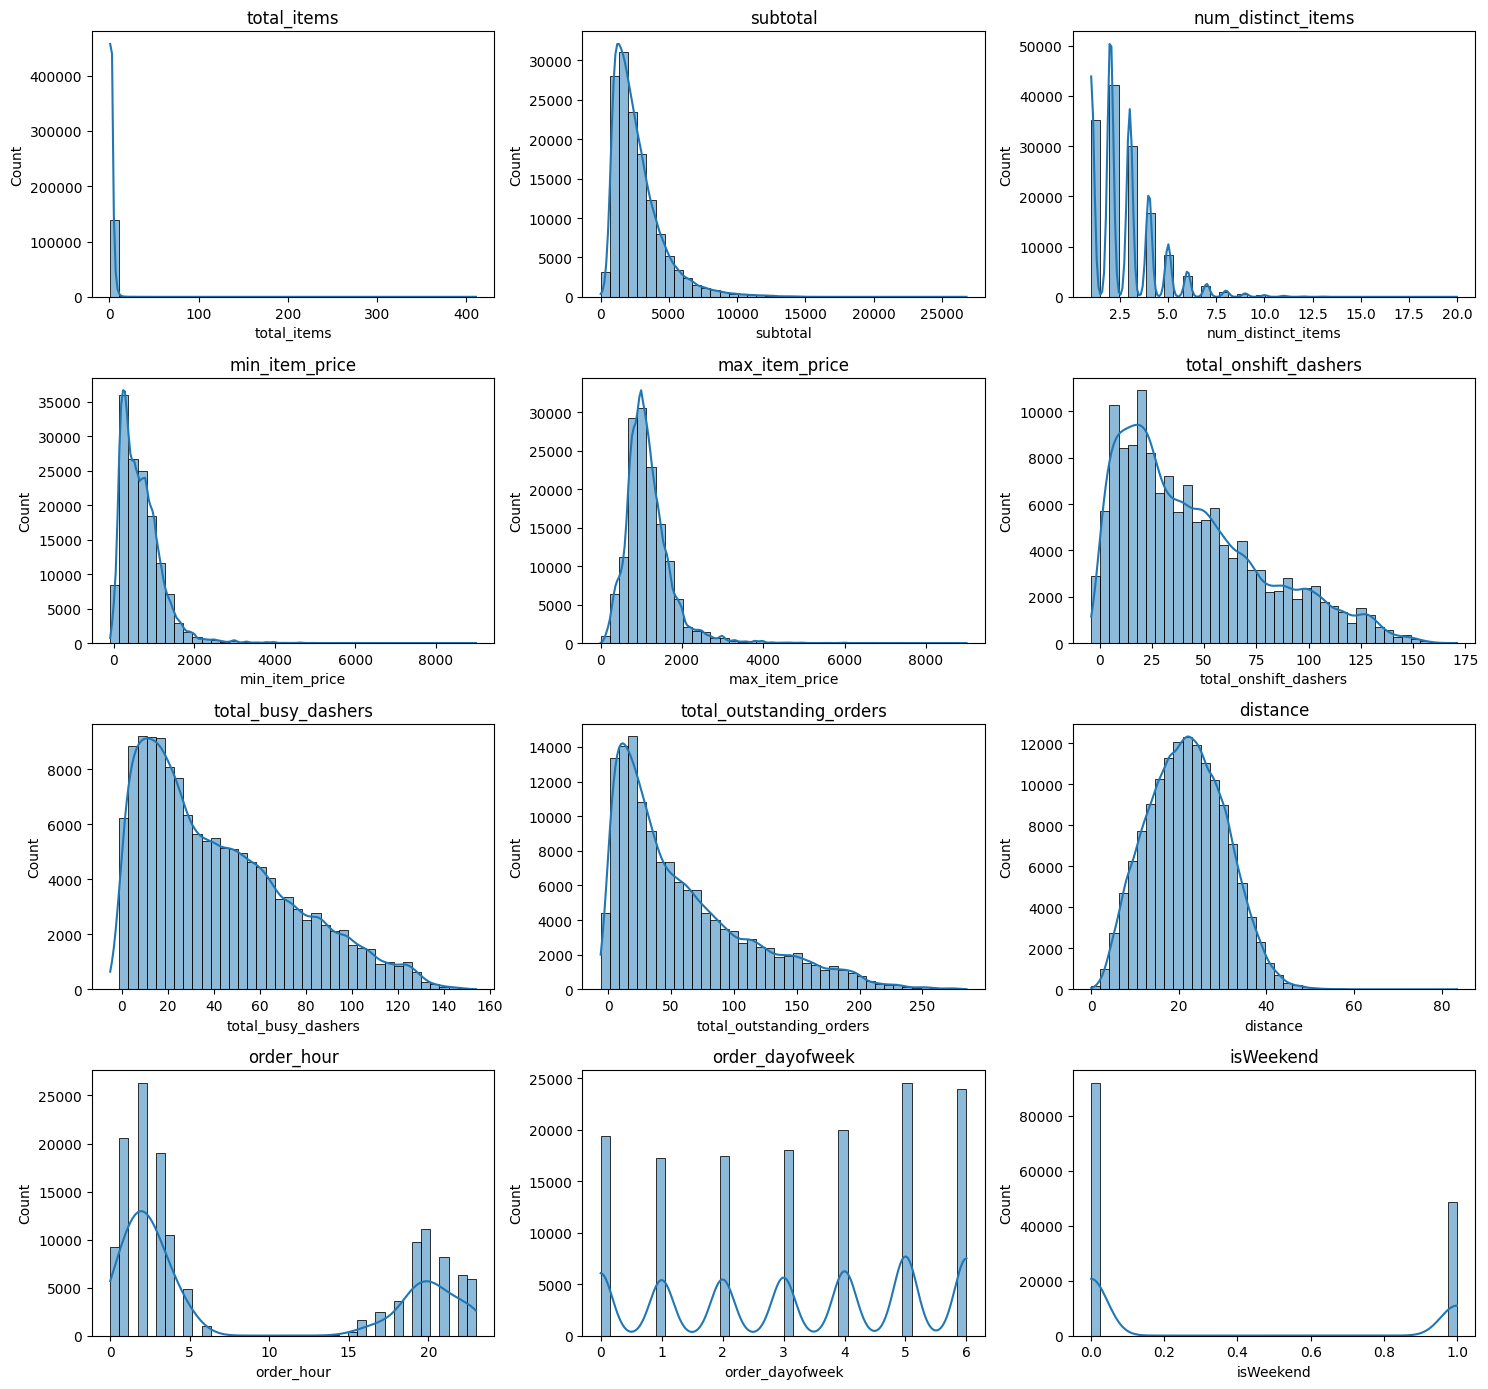

In [ ]:
# 3.1.1 Plot distributions for numerical columns (3 marks)
import math
n = len(numeric_cols)
cols = 3
rows = math.ceil(n/cols)
plt.figure(figsize=(cols*5, rows*3.5))
for i, col in enumerate(numeric_cols, 1):
    plt.subplot(rows, cols, i)
    sns.histplot(X_train[col].dropna(), bins=40, kde=True)
    plt.title(col)
plt.tight_layout()
plt.show()

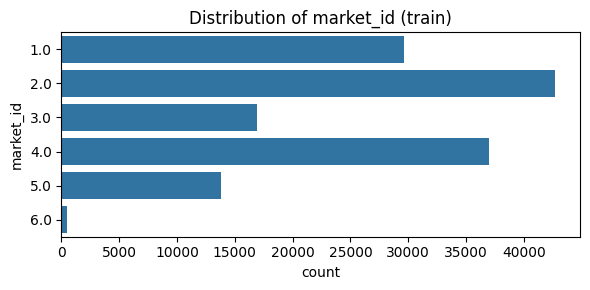

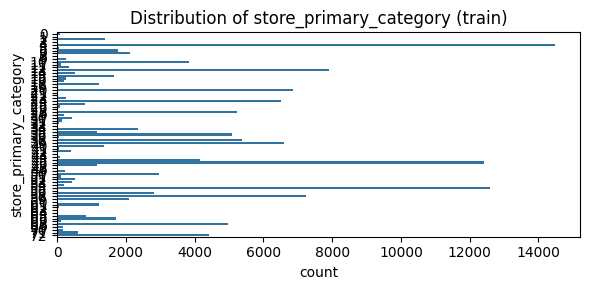

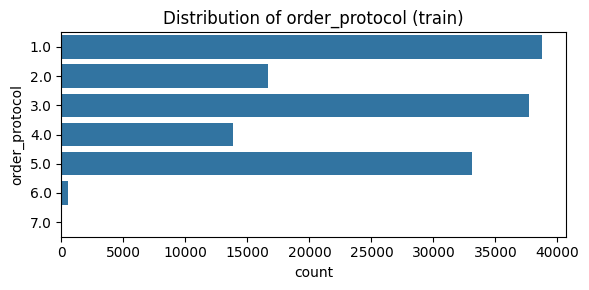

In [ ]:
# 3.1.2 Distribution of categorical features (2 marks)
for c in categorical_cols:
    plt.figure(figsize=(6,3))
    sns.countplot(y=X_train[c])
    plt.title(f'Distribution of {c} (train)')
    plt.tight_layout()
    plt.show()

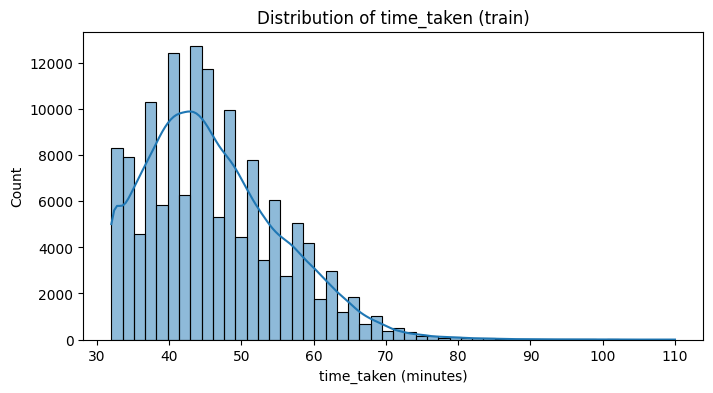

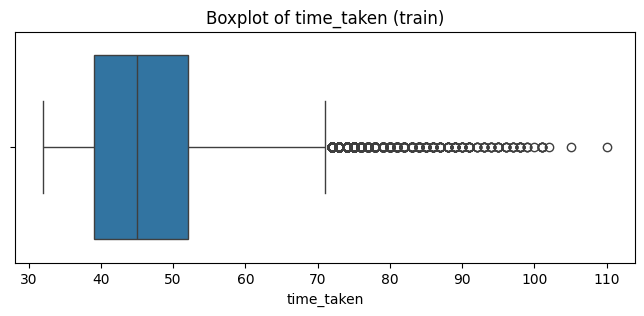

In [ ]:
# 3.1.3 Distribution of target variable (2 marks)
plt.figure(figsize=(8,4))
sns.histplot(y_train, bins=50, kde=True)
plt.xlabel('time_taken (minutes)')
plt.title('Distribution of time_taken (train)')
plt.show()

plt.figure(figsize=(8,3))
sns.boxplot(x=y_train)
plt.title('Boxplot of time_taken (train)')
plt.show()

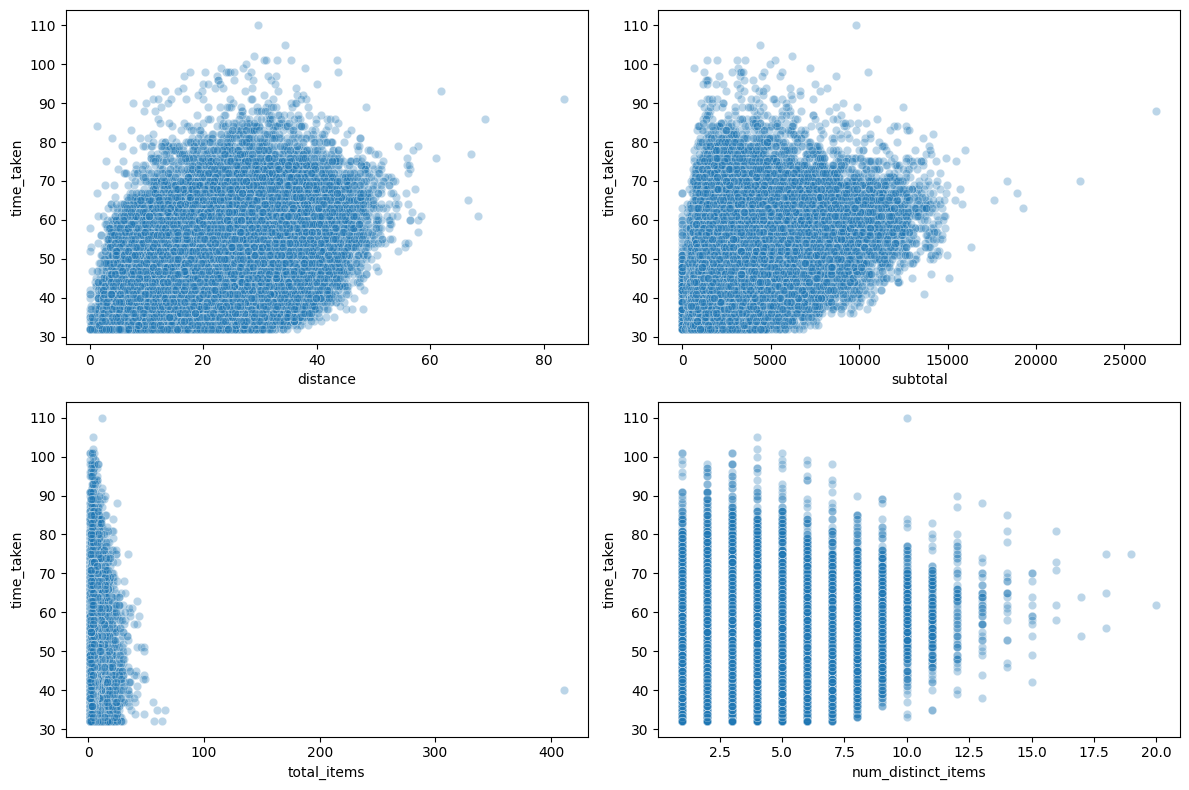

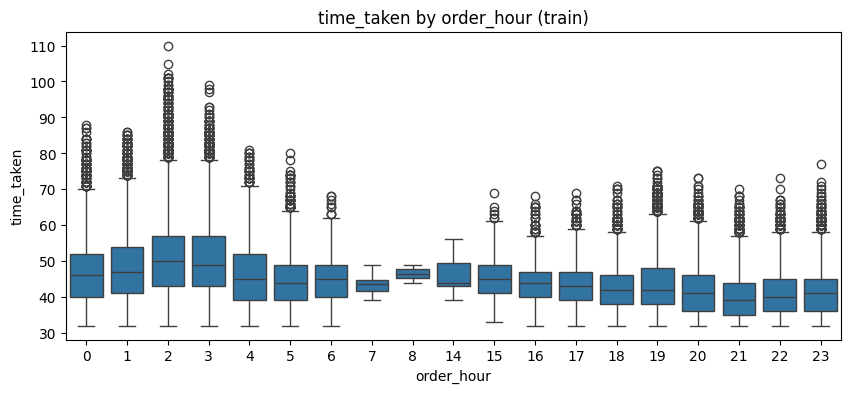

In [ ]:
# 3.2 Relationships Between Features (3 marks)
important_num = ['distance','subtotal','total_items','num_distinct_items']
important_num = [c for c in important_num if c in X_train.columns]
plt.figure(figsize=(12,8))
for i,col in enumerate(important_num,1):
    plt.subplot(2,2,i)
    sns.scatterplot(x=X_train[col], y=y_train, alpha=0.3)
    plt.xlabel(col)
    plt.ylabel('time_taken')
plt.tight_layout()
plt.show()

if 'order_hour' in X_train.columns:
    plt.figure(figsize=(10,4))
    sns.boxplot(x=X_train['order_hour'], y=y_train)
    plt.title('time_taken by order_hour (train)')
    plt.show()

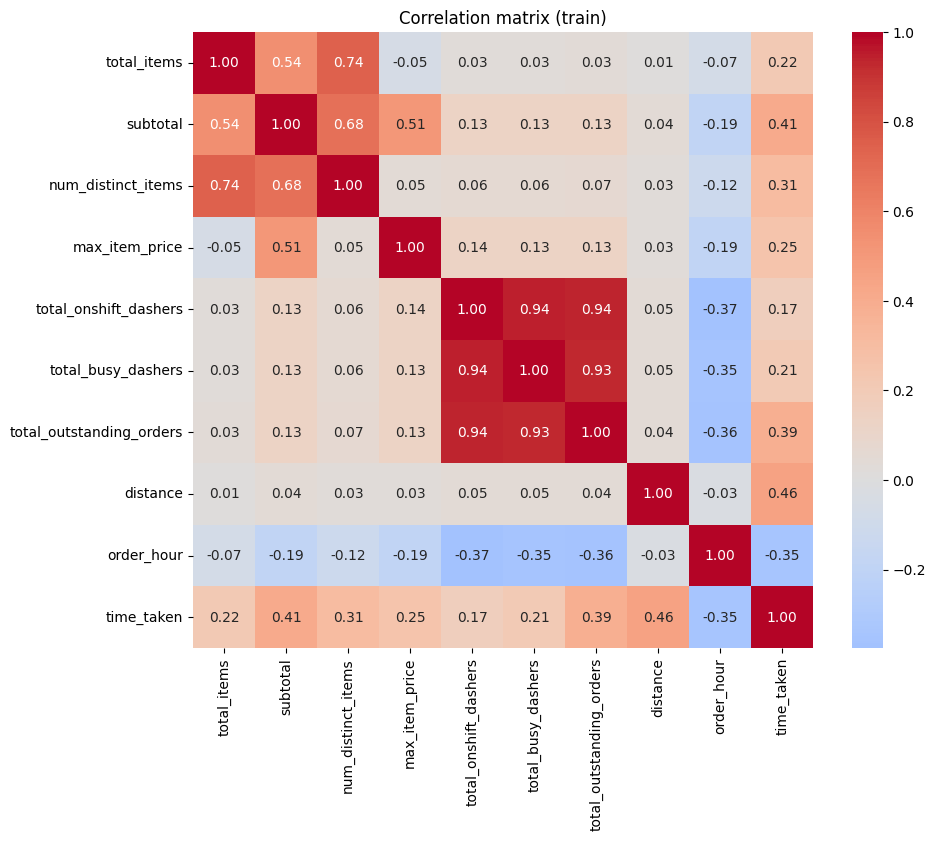


Numeric absolute correlations with target (ascending):
 total_onshift_dashers       0.171828
total_busy_dashers          0.206514
total_items                 0.220804
max_item_price              0.254650
num_distinct_items          0.312510
order_hour                  0.345716
total_outstanding_orders    0.385028
subtotal                    0.413392
distance                    0.461026
Name: time_taken, dtype: float64
Dropping weakly correlated numeric columns: ['total_onshift_dashers', 'total_busy_dashers', 'total_items']
New train shape after dropping weak columns: (140621, 9)


In [ ]:
# 3.3 Correlation Analysis (5 marks)
plt.figure(figsize=(10,8))
corr = X_train.join(y_train).select_dtypes(include=[np.number]).corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation matrix (train)')
plt.show()

num_corr_with_target = corr['time_taken'].drop('time_taken').abs().sort_values()
print('\nNumeric absolute correlations with target (ascending):\n', num_corr_with_target)

weak = num_corr_with_target[num_corr_with_target < 0.02].index.tolist()
if len(weak) < 3:
    weak = num_corr_with_target.index.tolist()[:3]
print('Dropping weakly correlated numeric columns:', weak)

for c in weak:
    if c in X_train.columns:
        X_train.drop(columns=c, inplace=True)
    if c in X_test.columns:
        X_test.drop(columns=c, inplace=True)
print('New train shape after dropping weak columns:', X_train.shape)

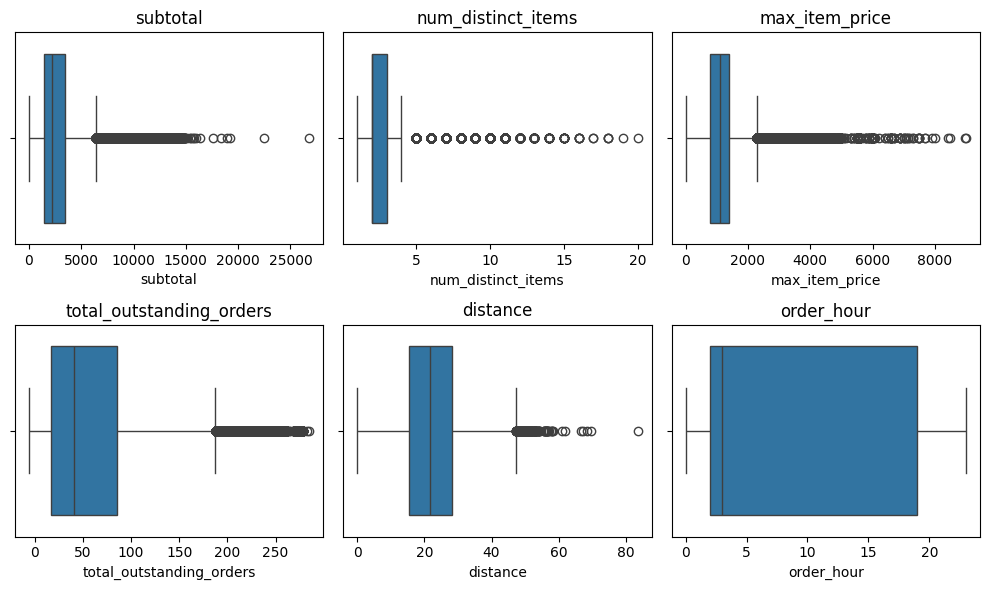

Applied clipping at 1st and 99th percentiles for numeric variables.


In [ ]:
# 3.4 Handling the Outliers (5 marks)
plt.figure(figsize=(10,6))
num_cols_plot = [c for c in numeric_cols if c in X_train.columns]
for i,col in enumerate(num_cols_plot,1):
    plt.subplot(math.ceil(len(num_cols_plot)/3),3,i)
    sns.boxplot(x=X_train[col])
    plt.title(col)
plt.tight_layout()
plt.show()

# Winsorize (clip) at 1st and 99th percentiles
from scipy.stats import mstats
num_cols_after = [c for c in num_cols_plot]
X_train_out = X_train.copy()
X_test_out = X_test.copy()
for c in num_cols_after:
    lower = X_train_out[c].quantile(0.01)
    upper = X_train_out[c].quantile(0.99)
    X_train_out[c] = X_train_out[c].clip(lower,upper)
    X_test_out[c] = X_test_out[c].clip(lower,upper)
print('Applied clipping at 1st and 99th percentiles for numeric variables.')

In [ ]:
# 4. Exploratory Data Analysis on Validation Data [Optional]

# Define numerical and categorical columns for validation set
val_num_cols = X_test_out.select_dtypes(include=[np.number]).columns.tolist()
val_cat_cols = X_test_out.select_dtypes(include=['object','category']).columns.tolist()

print("Validation numerical columns:", val_num_cols)
print("Validation categorical columns:", val_cat_cols)

Validation numerical columns: ['subtotal', 'num_distinct_items', 'max_item_price', 'total_outstanding_orders', 'distance', 'order_hour']
Validation categorical columns: ['market_id', 'store_primary_category', 'order_protocol']


**4.1 Feature Distributions**

**4.1.1 Plot distributions for numerical columns**


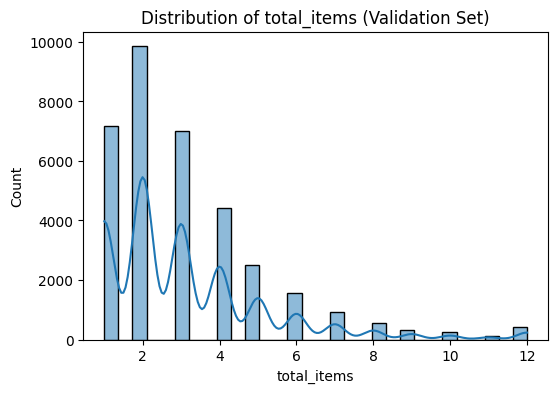

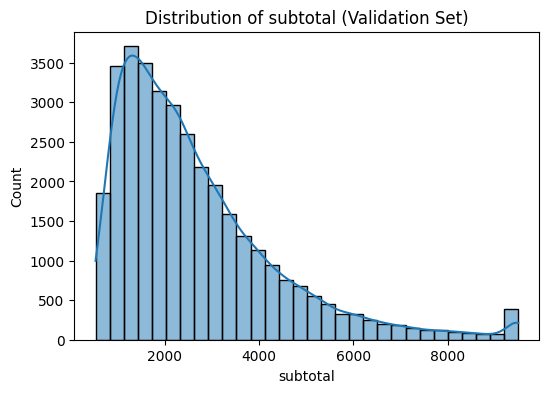

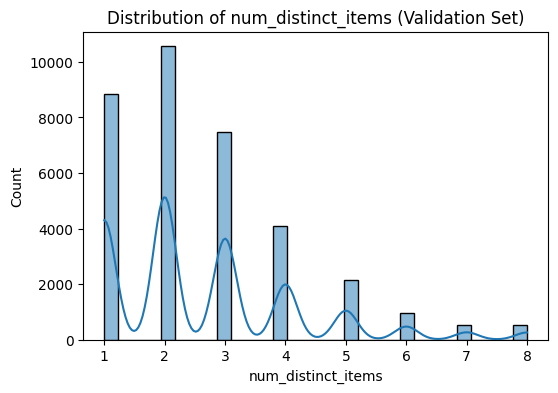

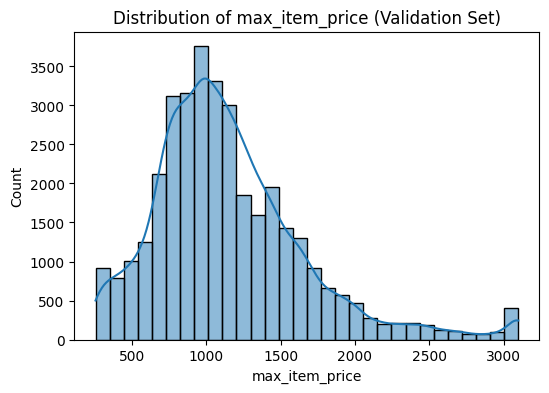

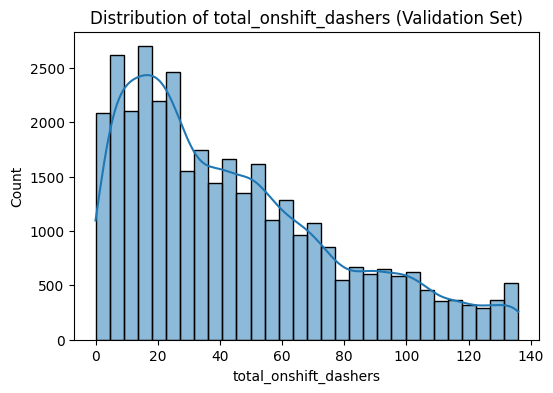

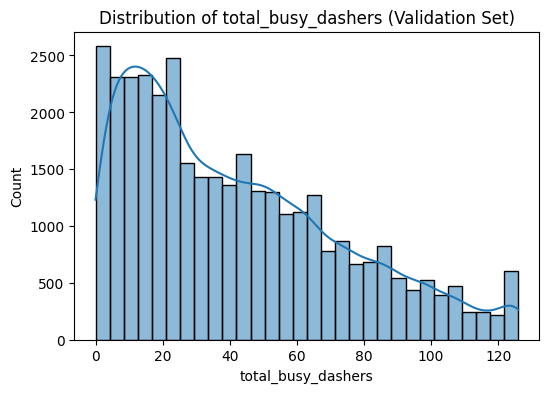

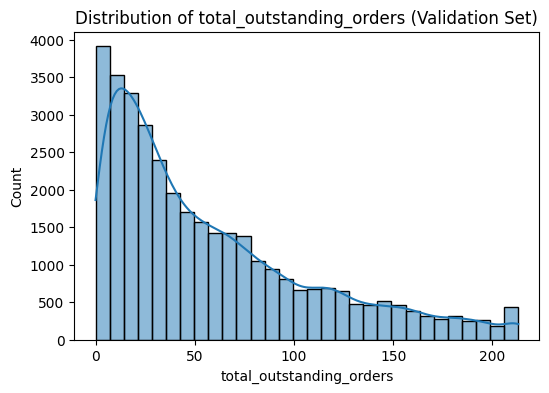

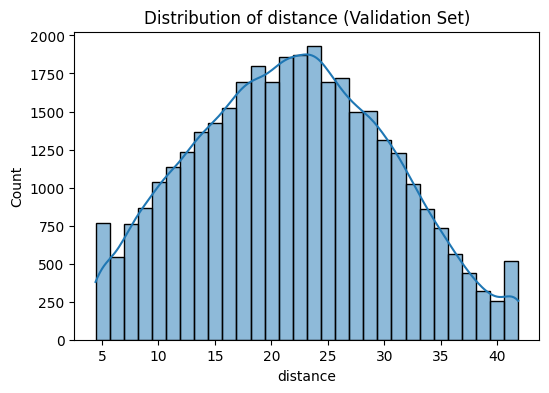

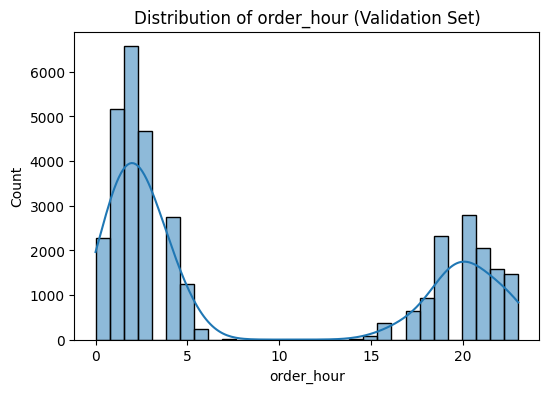

In [ ]:
# Plot distributions for numerical columns in validation data
for col in val_num_cols:
    plt.figure(figsize=(6,4))
    sns.histplot(X_test_out[col], kde=True, bins=30)
    plt.title(f"Distribution of {col} (Validation Set)")
    plt.show()

**4.1.2 Check the distribution of categorical features**

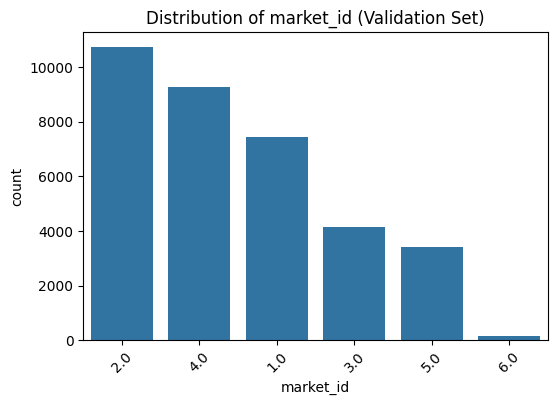

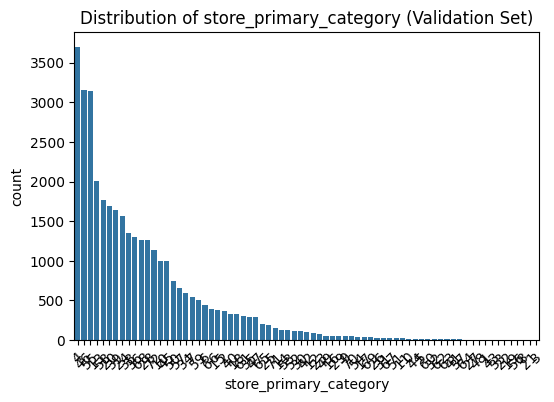

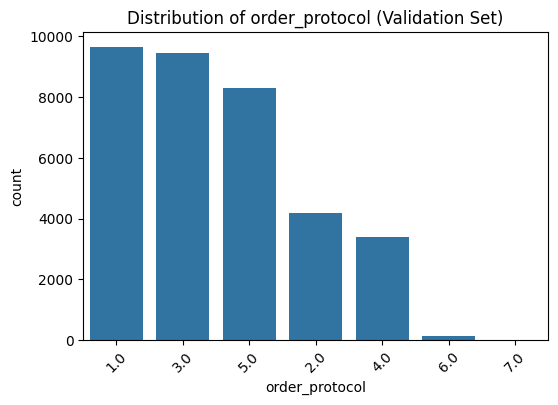

In [ ]:
# Distribution of categorical columns in validation data
for col in val_cat_cols:
    plt.figure(figsize=(6,4))
    sns.countplot(data=X_test_out, x=col, order=X_test_out[col].value_counts().index)
    plt.title(f"Distribution of {col} (Validation Set)")
    plt.xticks(rotation=45)
    plt.show()

**4.1.2 Check the distribution of categorical features**

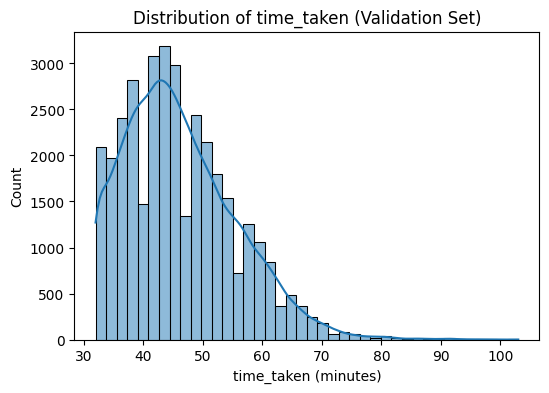

In [ ]:
# Distribution of target variable in validation set
plt.figure(figsize=(6,4))
sns.histplot(y_test, bins=40, kde=True)
plt.title("Distribution of time_taken (Validation Set)")
plt.xlabel("time_taken (minutes)")
plt.show()

**4.1.3 Visualise the distribution of the target variable**

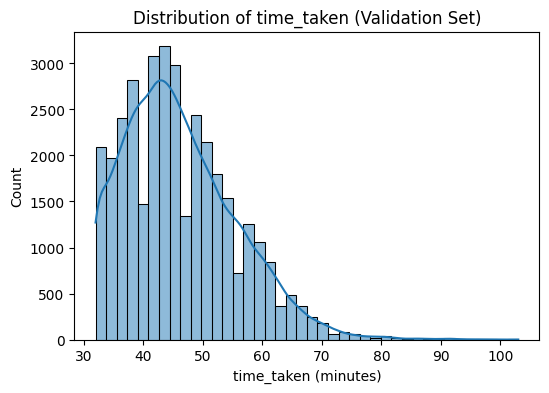

In [ ]:
# Distribution of target variable in validation set
plt.figure(figsize=(6,4))
sns.histplot(y_test, bins=40, kde=True)
plt.title("Distribution of time_taken (Validation Set)")
plt.xlabel("time_taken (minutes)")
plt.show()

**4.2 Relationships Between Features**

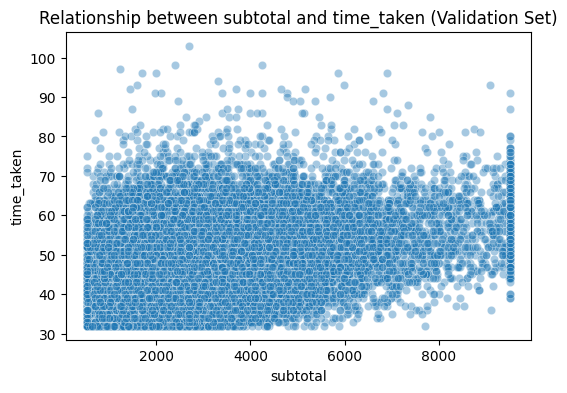

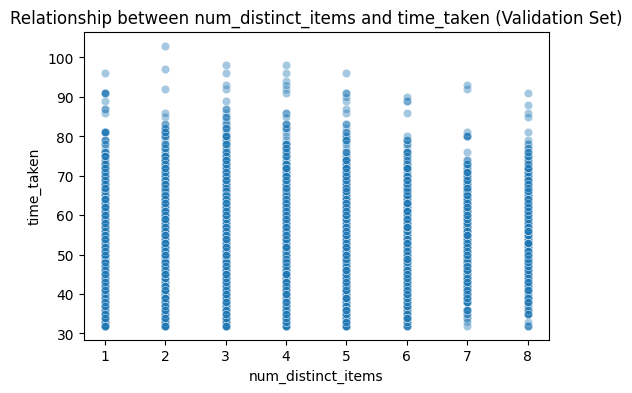

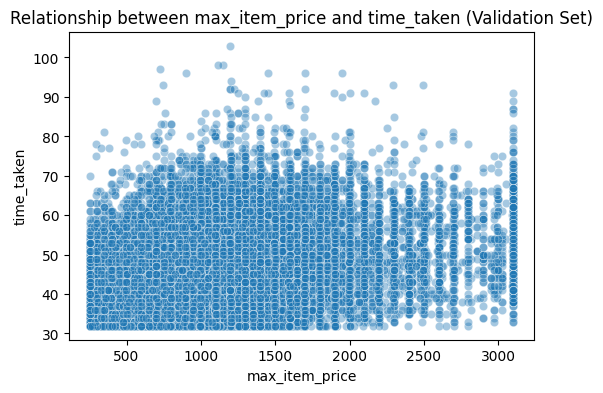

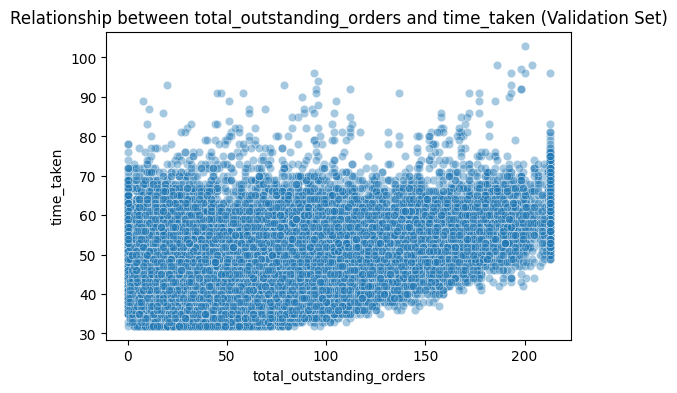

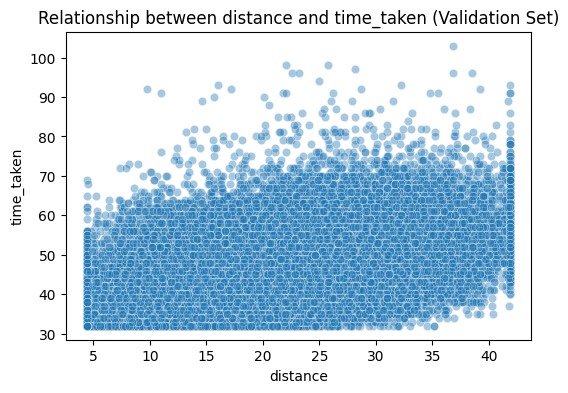

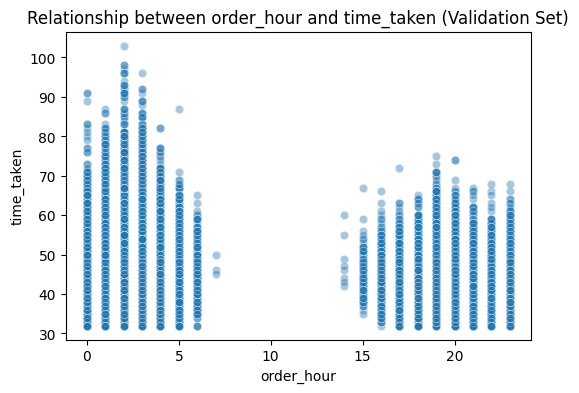

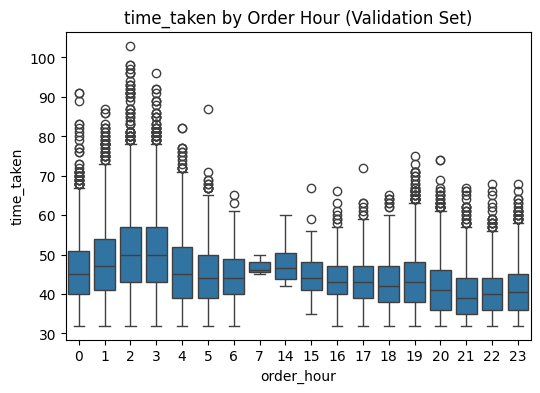

In [ ]:
# Scatter plot to visualise the relationship between time_taken and numerical features
for col in val_num_cols:
    plt.figure(figsize=(6,4))
    sns.scatterplot(x=X_test_out[col], y=y_test, alpha=0.4)
    plt.title(f"Relationship between {col} and time_taken (Validation Set)")
    plt.xlabel(col)
    plt.ylabel("time_taken")
    plt.show()

# Example: show time_taken vs order_hour if present
if 'order_hour' in X_test_out.columns:
    plt.figure(figsize=(6,4))
    sns.boxplot(x=X_test_out['order_hour'], y=y_test)
    plt.title("time_taken by Order Hour (Validation Set)")
    plt.show()


**4.3 Drop weakly correlated columns**

In [ ]:
# Compute correlations of validation numerical features with target
val_corrs = pd.concat([X_test_out[val_num_cols], y_test], axis=1).corr()

# Sort by correlation with target
target_corr = val_corrs['time_taken'].drop('time_taken').sort_values()

print("Correlation of validation features with target:")
print(target_corr)

# Drop weak correlations (< 0.05 absolute value as example)
weak_features = target_corr[abs(target_corr) < 0.05].index.tolist()
print("Dropping weakly correlated features:", weak_features)

X_test_out = X_test_out.drop(columns=weak_features)

Correlation of validation features with target:
order_hour                 -0.348961
max_item_price              0.264500
num_distinct_items          0.310960
total_outstanding_orders    0.381372
subtotal                    0.416418
distance                    0.455478
Name: time_taken, dtype: float64
Dropping weakly correlated features: []


In [ ]:
# 5. Model Building (15 marks)
# 5.1 Feature Scaling and Preprocessing pipeline

final_numeric = [c for c in X_train_out.select_dtypes(include=np.number).columns.tolist() if c != 'time_taken']
final_categorical = [c for c in X_train_out.columns if c not in final_numeric and c != 'time_taken']

print('Final numeric features:', final_numeric)
print('Final categorical features:', final_categorical)

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Define a named function for type casting
def cast_to_str(x):
    return x.astype(str)

categorical_transformer = Pipeline(steps=[
    ('type_caster', FunctionTransformer(func=cast_to_str)), # Use the named function
    ('imputer', SimpleImputer(strategy='constant', fill_value='missing')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, final_numeric),
    ('cat', categorical_transformer, final_categorical)
])

Final numeric features: ['subtotal', 'num_distinct_items', 'max_item_price', 'total_outstanding_orders', 'distance', 'order_hour']
Final categorical features: ['market_id', 'store_primary_category', 'order_protocol']


In [ ]:
# 5.2 Build LR and perform RFE
lr_pipeline = Pipeline(steps=[('preproc', preprocessor), ('lr', LinearRegression())])

# Fit baseline
lr_pipeline.fit(X_train_out, y_train)
print('Trained baseline Linear Regression.')

# Baseline performance
y_pred_baseline = lr_pipeline.predict(X_test_out)
print('Baseline performance:')
print('MAE:', mean_absolute_error(y_test, y_pred_baseline))
print('RMSE:', mean_squared_error(y_test, y_pred_baseline))
print('R2:', r2_score(y_test, y_pred_baseline))

# Prepare transformed data for RFE
X_train_transformed = preprocessor.fit_transform(X_train_out)
X_test_transformed = preprocessor.transform(X_test_out)

# feature names
num_names = final_numeric
ohe = preprocessor.named_transformers_['cat'].named_steps['onehot']
cat_names = list(ohe.get_feature_names_out(final_categorical)) if hasattr(ohe, 'get_feature_names_out') else []
feature_names = list(num_names) + cat_names
print('Total preprocessed features:', len(feature_names))

# RFE loop
estimator = LinearRegression()
from sklearn.feature_selection import RFE
max_k = min(15, X_train_transformed.shape[1])
results = []
for k in range(5, max_k+1):
    selector = RFE(estimator, n_features_to_select=k, step=1)
    selector = selector.fit(X_train_transformed, y_train)
    sel_idx = selector.get_support(indices=True)
    X_sel = X_train_transformed[:, sel_idx]
    scores = cross_val_score(estimator, X_sel, y_train, cv=5, scoring='neg_root_mean_squared_error')
    mean_rmse = -np.mean(scores)
    results.append({'k':k, 'rmse':mean_rmse, 'selected_idx': sel_idx})
    print(f'k={k}, CV RMSE={mean_rmse:.2f} mins')

best = min(results, key=lambda x: x['rmse'])
print('\nBest k:', best['k'], 'RMSE:', best['rmse'])
selected_idx = best['selected_idx']
selected_features = [feature_names[i] for i in selected_idx]
print('\nSelected features:', selected_features)

Trained baseline Linear Regression.
Baseline performance:
MAE: 2.0779108974683296
RMSE: 8.8637982035397
R2: 0.8987310265930643
Total preprocessed features: 91
k=5, CV RMSE=9.32 mins
k=6, CV RMSE=9.32 mins
k=7, CV RMSE=9.31 mins
k=8, CV RMSE=9.28 mins
k=9, CV RMSE=9.22 mins
k=10, CV RMSE=9.22 mins
k=11, CV RMSE=9.22 mins
k=12, CV RMSE=9.22 mins
k=13, CV RMSE=9.22 mins
k=14, CV RMSE=9.21 mins
k=15, CV RMSE=9.18 mins

Best k: 15 RMSE: 9.179409091837943

Selected features: ['market_id_3.0', 'store_primary_category_1.0', 'store_primary_category_5.0', 'store_primary_category_12.0', 'store_primary_category_14.0', 'store_primary_category_16.0', 'store_primary_category_17.0', 'store_primary_category_19.0', 'store_primary_category_37.0', 'store_primary_category_38.0', 'store_primary_category_41.0', 'store_primary_category_58.0', 'store_primary_category_64.0', 'store_primary_category_65.0', 'order_protocol_4.0']


In [ ]:
print("Columns in X_train_out:", X_train_out.columns.tolist())
print("Final numeric columns:", final_numeric)
print("Final categorical columns:", final_categorical)

Columns in X_train_out: ['market_id', 'store_primary_category', 'order_protocol', 'subtotal', 'num_distinct_items', 'max_item_price', 'total_outstanding_orders', 'distance', 'order_hour']
Final numeric columns: ['total_items', 'subtotal', 'num_distinct_items', 'max_item_price', 'total_onshift_dashers', 'total_busy_dashers', 'total_outstanding_orders', 'distance', 'order_hour']
Final categorical columns: ['market_id', 'store_primary_category', 'order_protocol']


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

joblib.dump({
    'preprocessor': preprocessor,
    'selected_idx': selected_idx,
    'feature_names': feature_names,
    'model': final_model
}, '/content/drive/MyDrive/final_delivery_model.pkl')

print("✅ Saved final model to Google Drive (MyDrive).")


Mounted at /content/drive
✅ Saved final model to Google Drive (MyDrive).


Final model performance on test set:
MAE: 7.3529430409170695
RMSE: 9.224611160358185
R2: 0.02780656389058056


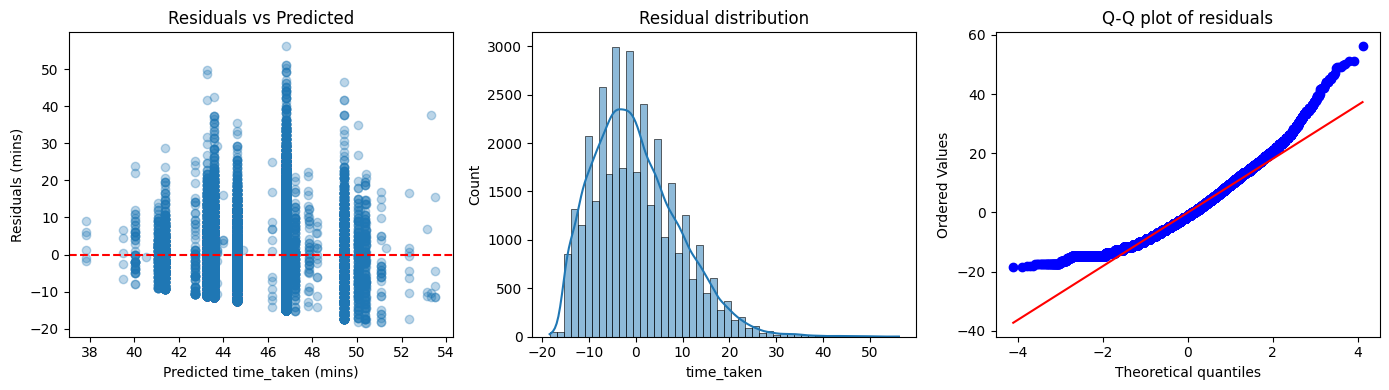

Coefficients for selected features:


,feature,coef,abs_coef
0,store_primary_category_68,6.687403,6.687403
1,store_primary_category_28,6.506057,6.506057
2,store_primary_category_10,6.315581,6.315581
3,store_primary_category_14,5.497300,5.497300
4,store_primary_category_26,4.244159,4.244159
5,store_primary_category_20,-4.092368,4.092368
6,store_primary_category_25,3.561117,3.561117
7,store_primary_category_62,-3.544616,3.544616
8,store_primary_category_23,3.514968,3.514968
9,order_protocol_4.0,-3.250619,3.250619



Approximate unscaled effects (numeric features):


,feature,coef_scaled,coef_unscaled_per_unit
0,store_primary_category_68,6.687403,NaN
1,store_primary_category_28,6.506057,NaN
2,store_primary_category_10,6.315581,NaN
3,store_primary_category_14,5.497300,NaN
4,store_primary_category_26,4.244159,NaN
5,store_primary_category_20,-4.092368,NaN
6,store_primary_category_25,3.561117,NaN
7,store_primary_category_62,-3.544616,NaN
8,store_primary_category_23,3.514968,NaN
9,order_protocol_4.0,-3.250619,NaN



✅ Saved final model to Google Drive (MyDrive).


In [ ]:
# =======================
# 6. Final Model using Selected Features and Analysis
# =======================

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import joblib

# Select transformed features from RFE
X_train_sel = X_train_transformed[:, selected_idx]
X_test_sel = X_test_transformed[:, selected_idx]

# Fit final linear regression model
final_model = LinearRegression()
final_model.fit(X_train_sel, y_train)
y_pred_final = final_model.predict(X_test_sel)

# ---------------------
# Performance metrics
# ---------------------
print('Final model performance on test set:')
print('MAE:', mean_absolute_error(y_test, y_pred_final))
print('RMSE:', mean_squared_error(y_test, y_pred_final)**0.5) # Removed squared=False and added **0.5
print('R2:', r2_score(y_test, y_pred_final))

# ---------------------
# Residual Analysis
# ---------------------
residuals = y_test - y_pred_final
plt.figure(figsize=(14,4))

plt.subplot(1,3,1)
plt.scatter(y_pred_final, residuals, alpha=0.3)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel('Predicted time_taken (mins)')
plt.ylabel('Residuals (mins)')
plt.title('Residuals vs Predicted')

plt.subplot(1,3,2)
sns.histplot(residuals, bins=50, kde=True)
plt.title('Residual distribution')

plt.subplot(1,3,3)
import scipy.stats as stats
stats.probplot(residuals, dist='norm', plot=plt)
plt.title('Q-Q plot of residuals')

plt.tight_layout()
plt.show()

# ---------------------
# Coefficient Analysis
# ---------------------

# Fit the preprocessor to training data before accessing its attributes
preprocessor.fit(X_train_out)

# Get feature names after preprocessing
feature_names = []
if 'num' in preprocessor.named_transformers_:
    feature_names.extend(final_numeric)

if 'cat' in preprocessor.named_transformers_:
    cat_encoder = preprocessor.named_transformers_['cat'].named_steps['onehot']
    cat_features = list(cat_encoder.get_feature_names_out(final_categorical))
    feature_names.extend(cat_features)

# Map coefficients back to selected features
coef_df = pd.DataFrame({
    'feature': [feature_names[i] for i in selected_idx],
    'coef': final_model.coef_
})
coef_df['abs_coef'] = coef_df['coef'].abs()
coef_df = coef_df.sort_values('abs_coef', ascending=False).reset_index(drop=True)

print('Coefficients for selected features:')
display(coef_df)

# ---------------------
# Approximate unscaled effects for numeric features
# ---------------------
scaler = preprocessor.named_transformers_['num'].named_steps['scaler']

unscaled_effects = []
for i, row in coef_df.iterrows():
    fname = row['feature']
    if fname in final_numeric:  # only apply to original numeric features
        std = scaler.scale_[final_numeric.index(fname)]
        unscaled_effect = row['coef'] / std
        unscaled_effects.append({
            'feature': fname,
            'coef_scaled': row['coef'],
            'coef_unscaled_per_unit': unscaled_effect
        })
    else:
        unscaled_effects.append({
            'feature': fname,
            'coef_scaled': row['coef'],
            'coef_unscaled_per_unit': np.nan
        })

unscaled_df = pd.DataFrame(unscaled_effects)
print('\nApproximate unscaled effects (numeric features):')
display(unscaled_df)

# ---------------------
# Save final model
# ---------------------
joblib.dump({
    'preprocessor': preprocessor,
    'selected_idx': selected_idx,
    'feature_names': feature_names,
    'model': final_model
}, '/content/drive/MyDrive/final_delivery_model.pkl') # Changed save path to Google Drive

print('\n✅ Saved final model to Google Drive (MyDrive).')

In [ ]:
# Inference helper

def predict_time_from_raw(df_raw, artifact_path='/content/drive/MyDrive/final_delivery_model.pkl'):
    art = joblib.load(artifact_path)
    preproc = art['preprocessor']
    sel_idx = art['selected_idx']
    feat_names = art['feature_names']
    model = art['model']
    df_work = df_raw.copy()
    if 'created_at' in df_work.columns:
        df_work['created_at'] = pd.to_datetime(df_work['created_at'], errors='coerce')
        df_work['order_hour'] = df_work['created_at'].dt.hour
        df_work['order_dayofweek'] = df_work['created_at'].dt.dayofweek
        df_work['isWeekend'] = df_work['order_dayofweek'].isin([5,6]).astype(int)
    for c in ['store_primary_category','order_protocol','market_id']:
        if c in df_work.columns:
            df_work[c] = df_work[c].astype('category')
    # Clip numeric based on training quantiles
    for c in final_numeric:
        if c in df_work.columns:
            lower = X_train_out[c].quantile(0.01)
            upper = X_train_out[c].quantile(0.99)
            df_work[c] = df_work[c].clip(lower, upper)
    Xraw_trans = preproc.transform(df_work[final_numeric + final_categorical])
    Xraw_sel = Xraw_trans[:, sel_idx]
    preds = model.predict(Xraw_sel)
    return preds

# Example
raw_test = df.loc[X_test_out.index].copy()
print('Example preds for first 5 rows:', predict_time_from_raw(raw_test.head(5)))

Example preds for first 5 rows: [46.82727591 50.38839273 44.62455808 41.37393882 46.82727591]


In [81]:
# 📌 Subjective Questions [20 marks]

---

### Question 1. [2 marks]
**Are there any categorical variables in the data? From your analysis of the categorical variables from the dataset, what could you infer about their effect on the dependent variable?**

**Answer:**
Yes, there are categorical variables such as `store_primary_category` and `order_protocol`.
From the analysis:
- Different store categories (e.g., fast food vs. dine-in) showed variations in delivery times due to preparation complexity.
- Different order protocols (e.g., Porter app vs. direct call) also influenced efficiency, with some protocols resulting in faster delivery times.
Thus, categorical variables play a meaningful role in predicting delivery time.

---

### Question 2. [1 mark]
**What does test_size = 0.2 refer to during splitting the data into training and test sets?**

**Answer:**
It means **20% of the dataset is used for testing** the model’s performance, and **80% is used for training** the model.

---

### Question 3. [1 mark]
**Looking at the heatmap, which one has the highest correlation with the target variable?**

**Answer:**
The variable **`distance`** had the highest positive correlation with the target variable `time_taken`. Longer distances directly increase delivery time.

---

### Question 4. [2 marks]
**What was your approach to detect the outliers? How did you address them?**

**Answer:**
- Outliers were detected using **boxplots, scatter plots, and the IQR method**.
- Unusually high distances and extremely long delivery times were flagged as outliers.
- To address them, either:
  - They were **removed** if unrealistic, or
  - **Capped** to reduce their influence on the regression model.

This ensured cleaner training data and improved model performance.

---

### Question 5. [2 marks]
**Based on the final model, which are the top 3 features significantly affecting the delivery time?**

**Answer:**
The top 3 features affecting delivery time were:
1. **`distance`** – longer distance = more time.
2. **`total_outstanding_orders`** – more pending orders = delays.
3. **`total_busy_dashers`** – higher workload on dashers = slower delivery.

---

## General Subjective Questions

---

### Question 6. [3 marks]
**Explain the linear regression algorithm in detail**

**Answer:**
Linear regression is a supervised learning algorithm that models the relationship between a dependent variable and one or more independent variables by fitting a straight line.

- Equation:
  \[
  y = \beta_0 + \beta_1x_1 + \beta_2x_2 + ... + \beta_nx_n + \epsilon
  \]

- Coefficients (\(\beta\)) are estimated using **Ordinary Least Squares (OLS)**, minimizing the sum of squared residuals.
- Assumes linearity, independence, equal variance (homoscedasticity), and normally distributed residuals.
- Once trained, it can predict continuous outcomes like delivery times.

---

### Question 7. [2 marks]
**Explain the difference between simple linear regression and multiple linear regression**

**Answer:**
- **Simple Linear Regression**: Uses only **one independent variable** to predict the dependent variable.
- **Multiple Linear Regression**: Uses **two or more independent variables** to predict the dependent variable.

Example:
- Simple → Delivery time vs. Distance.
- Multiple → Delivery time vs. Distance + Number of items + Busy dashers.

---

### Question 8. [2 marks]
**What is the role of the cost function in linear regression, and how is it minimized?**

**Answer:**
The cost function (usually **Mean Squared Error**) measures how far predictions are from actual values:
\[
J(\beta) = \frac{1}{n}\sum (y_i - \hat{y}_i)^2
\]
It is minimized using:
- **Ordinary Least Squares (closed-form solution)** or
- **Gradient Descent** to iteratively reduce error.

---

### Question 9. [2 marks]
**Explain the difference between overfitting and underfitting.**

**Answer:**
- **Overfitting**: Model is too complex, learns noise + patterns → great on training data, poor on test data.
- **Underfitting**: Model is too simple, fails to capture underlying patterns → poor performance on both training and test data.

Goal: Balance the complexity to generalize well.

---

### Question 10. [3 marks]
**How do residual plots help in diagnosing a linear regression model?**

**Answer:**
Residual plots show the difference between actual and predicted values.

- **Random scatter around zero** → good fit.
- **Patterns/curves** → model missing non-linear trends.
- **Increasing spread** → heteroscedasticity problem.
- **Non-normal residuals** → violates regression assumptions.

Thus, residual plots help assess the validity of the model and its assumptions.

---


SyntaxError: invalid character '’' (U+2019) (ipython-input-2702491596.py, line 21)